In [2]:
from __future__ import annotations #Этот импорт превращает все аннотации в строки, которые не вычисляются во время выполнения, а только при явном запросе
import math
import copy
from dataclasses import dataclass #декоратор для автогенерации __init__, __repr__, __eq__ и т.д. по аннотациям полей класса.

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split

torch.manual_seed(0)
np.random.seed(0)

# =======================================================================================
# БЛОК 1. ЯЧЕЙКА LIQUID TIME-CONSTANT (LTC) — сердце сети
# =======================================================================================
считает и возвращает внутреннее состояние x только для ОДНОГО (конкретного) момента времени t.

In [3]:
class LiquidTimeConstantCell(nn.Module): #без наследования от nn.Module тензоры W, V, bias, tau_raw были бы просто атрибутами объекта — PyTorch их бы не «увидел», и torch.optim.AdamW(model.parameters()) получил бы пустой список.
    """
    Один шаг рекуррентной "жидкостной" динамики, реализующий уравнения:

        I(t)      = W x(t) + V u(t) + b
        f(I(t))   = tanh(I(t))
        dx/dt     = (-x(t) + f(I(t))) / tau
        x(t+dt)   = x(t) + dt * dx/dt      


    В отличие от классического RNN, здесь есть явная "постоянная времени" tau —
    она определяет, насколько быстро состояние "забывает" прошлое и "тянется"
    к новому входу. tau — ОБУЧАЕМЫЙ параметр на каждый нейрон скрытого слоя.

    Два вызова:
    LiquidTimeConstantCell(1, 32, dt=1.0, unfold_steps=2). W = Linear(hidden = 32, hidden = 32) V = Linear(input=1, hidden=32) bias=32
    LiquidTimeConstantCell(32, 16, dt=1.0, unfold_steps=2). . W = Linear(hidden = 16, hidden = 16) V = Linear(input=32, hidden=16) bias=16
    """

    def __init__(self, input_size: int, hidden_size: int, #«конструктор» выполняется один раз
                 dt: float = 1.0, unfold_steps: int = 1): #сколько чисел на входе (input_size), сколько «нейронов» внутри (hidden_size), и два числа с значениями по умолчанию, если их не указать (dt=1.0, unfold_steps=1)
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.dt = dt #Запоминаем шаг времени.
        # unfold_steps: сколько мелких Эйлер-шагов делаем ВНУТРИ одного "тика" t.
        # Это повышает численную устойчивость и точность интегрирования ODE,
        # не увеличивая длину последовательности, которую видит модель.
        self.unfold_steps = unfold_steps


#матрица чисел(hidden_size × hidden_size) - чтобы превратить «текущее состояние сети» в «вклад в общий сигнал»
        self.W = nn.Linear(hidden_size, hidden_size, bias=False)   # x(t) -> вклад в I(t)
#она превращает «входное число ряда» (например, значение температуры в момент времени t) во «вклад в общий сигнал» (input_size × hidden_size)
        self.V = nn.Linear(input_size, hidden_size, bias=False)    # u(t) -> вклад в I(t)
        self.bias = nn.Parameter(torch.zeros(hidden_size))

        # tau храним в "сыром" виде, tau = softplus(tau_raw) + eps  =>  tau > 0 всегда.
        # Инициализация в районе softplus(0.5) ~ 0.97 — разумная стартовая "память".
        self.tau_raw = nn.Parameter(torch.full((hidden_size,), 0.5))
        self.tau_eps = 1e-3

        # Инициализация Xavier задаёт весам W и V оптимальный начальный масштаб. 
        # Для LNN это критично, так как мы численно решаем дифференциальное уравнение 40 шагов подряд 
        # — без правильной инициализации динамика системы либо уйдёт в NaN из-за взрыва чисел, либо перестанет обучаться из-за затухания градиентов
        nn.init.xavier_uniform_(self.W.weight)
        nn.init.xavier_uniform_(self.V.weight)

    def tau(self) -> torch.Tensor:
        return torch.nn.functional.softplus(self.tau_raw) + self.tau_eps

    def forward(self, u_t: torch.Tensor, x_t: torch.Tensor) -> torch.Tensor:
        """
        u_t: (batch, input_size)  — вход в момент t
        x_t: (batch, hidden_size) — состояние в момент t
        Возвращает x(t + dt): (batch, hidden_size)
        """
        tau = self.tau()                      # (hidden_size,)
        sub_dt = self.dt / self.unfold_steps  # self.unfold_steps - 2, значит каждый тик делится на два

        x = x_t
        for _ in range(self.unfold_steps):
            I_t = self.W(x) + self.V(u_t) + self.bias      # I(t) = Wx + Vu + b
            f_t = torch.tanh(I_t)                           # f(I(t))
            dx_dt = (-x + f_t) / tau                        # dx/dt = (-x + f(I)) / tau
            x = x + sub_dt * dx_dt                          # шаг Эйлера
        return x

# =======================================================================================
# БЛОК 2. ПОЛНАЯ СЕТЬ: LTC-слой(и) + выходная голова
# =======================================================================================

In [4]:
class LiquidNeuralNetwork(nn.Module):
    """
    Многослойная LNN для прогнозирования временных рядов.

    Архитектура:
        input -> [LTC layer 1] -> LayerNorm -> Dropout
              -> [LTC layer 2] -> LayerNorm -> Dropout   (опционально)
              -> Linear head -> прогноз y_hat

    На выходе берём финальное состояние x_T последнего слоя (аналог "hidden state"
    в RNN) и пропускаем через линейную голову: y_hat = Wy * x_T + by.
    """

    def __init__(self, input_size: int, hidden_sizes: list[int],
                 output_size: int, dt: float = 1.0,
                 unfold_steps: int = 2, dropout: float = 0.1):
        super().__init__()
        self.layers = nn.ModuleList() # Список для хранения LTC-слоёв
        self.norms = nn.ModuleList()# Список для слоёв нормализации (LayerNorm)
        in_size = input_size
        
        for h in hidden_sizes:
            self.layers.append(LiquidTimeConstantCell(in_size, h, dt=dt,
                                                        unfold_steps=unfold_steps))
            self.norms.append(nn.LayerNorm(h))
            in_size = h # Выход текущего слоя становится входом для следующего

        self.dropout = nn.Dropout(dropout) # Защита от переобучения (случайно "выключает" 10% связей)
        self.head = nn.Linear(hidden_sizes[-1], output_size) # Линейный слой: превращает 16 состояний в output_size (1 прогноз)

#На вход поступает u_seq — тензор размерностью (batch_size, seq_len, input_size).
#Пример: (64, 40, 1) — 64 примера в батче, каждый состоит из 40 временных шагов по 1 значению.
    def forward(self, u_seq: torch.Tensor) -> torch.Tensor:
        """
        u_seq: (batch, seq_len, input_size)
        Возвращает: (batch, output_size)
        """
        batch_size, seq_len, _ = u_seq.shape
        device = u_seq.device

        # Инициализируем состояние каждого слоя нулями
        # 1. Сбрасываем скрытые состояния (states) всех слоёв в 0 в начале последовательности
        # states — это список из двух нулевых тензоров: [ (64, 32), (64, 16) ]. Это «чистая память» сети до начала обработки сигнала.
        states = [torch.zeros(batch_size, cell.hidden_size, device=device)
                  for cell in self.layers]

        layer_input = u_seq # Для 1-го слоя вход — это исходный сигнал (40 шагов)
        #Главный внешний цикл: Проход по слоям (for layer_idx, ...)
        for layer_idx, (cell, norm) in enumerate(zip(self.layers, self.norms)):
            x = states[layer_idx] # Берем начальное нулевое состояние для текущего слоя
            outputs = []
            #Внутренний цикл во времени: Проход по 40 шагам (for t in range(seq_len):)
            for t in range(seq_len):
                u_t = layer_input[:, t, :] # Вырезаем кусочек сигнала для момента времени t
                x = cell(u_t, x) # Пропускаем через LTC-ячейку -> получаем НОВОЕ состояние x_t
                outputs.append(x) # Сохраняем состояние x_t в список
            # Превращаем список из 40 тензоров размера (batch, hidden) в один тензор (batch, 40, hidden)
            layer_out = torch.stack(outputs, dim=1)     # (batch, seq_len, hidden)
            # Стабилизируем значения внутренних состояний
            layer_out = norm(layer_out)
            # Случайно зануляем часть значений для борьбы с переобучением
            # Передаём результат: теперь последовательность состояний текущего слоя 
            # становится ВХОДНЫМ СИГНАЛОМ для следующего LTC-слоя!
            layer_out = self.dropout(layer_out)
            layer_input = layer_out                      # вход для следующего слоя
# Берем ТОЛЬКО самое последнее состояние на 39-м шаге во времени (t = seq_len - 1 = 39)
        x_T = layer_input[:, -1, :]                       # Размерность: (batch, 16) финальное состояние
        y_hat = self.head(x_T) # Возвращаем готовое предсказание!
        return y_hat

#Когда сеть делает y_hat = model(u_seq), на выходе получается один тензор размером (64, 1)

создаётся искусственный временной ряд

       /\        /\
      /  \  /\  /  \
 ___ /    \/  \/    \___
 он состоит из:
нескольких синусоид;
небольшого тренда;
случайного шума.

Это имитация реального сенсорного сигнала.

# =======================================================================================
# БЛОК 3. ДАННЫЕ: синтетический, но реалистичный временной ряд
# =======================================================================================

In [5]:
def generate_time_series(n_points: int, noise_std: float = 0.05) -> np.ndarray:
    """
    Сигнал = сумма нескольких синусоид разной частоты/фазы + слабый тренд + шум.
    Это имитирует типичный "сенсорный" сигнал (температура, вибрация, ЭКГ-подобные
    данные), на которых LNN показывают преимущество за счёт непрерывной динамики
    и устойчивости к неравномерным временным шагам.
    """
    t = np.linspace(0, 60 * math.pi, n_points)
    signal = (
        1.0 * np.sin(t * 0.5) # Компонента 1: Низкая частота (Основной ритм)
        + 0.5 * np.sin(t * 1.7 + 0.3)  # Компонента 2: Средняя частота + сдвиг фазы
        + 0.3 * np.sin(t * 3.1 + 1.1)   # Компонента 3: Высокая частота + сдвиг фазы
        + 0.002 * t                       # лёгкий тренд
    )
    signal += np.random.normal(0, noise_std, size=n_points) # Случайный шум
    return signal.astype(np.float32)


class TimeSeriesWindowDataset(Dataset):
    """
    Скользящее окно: по SEQ_LEN прошлым точкам предсказываем значение
    через HORIZON шагов вперёд.
    
    Значит сеть получает 40 прошлых значений.
    Скользящее окно — это способ нарезки длинного ряда на обучающие куски. 
    Сеть учится по 40 прошлым точкам смотреть сразу на 5 шагов вперед, выдавая одно целевое число

    Размер скользящего окна (seq_len) — это длина памяти, которую вы даёте сети в один момент времени.
    """

    def __init__(self, series: np.ndarray, seq_len: int, horizon: int):
        self.seq_len = seq_len
        self.horizon = horizon
        self.series = series
        self.n_samples = len(series) - seq_len - horizon + 1

    def __len__(self):
        return max(0, self.n_samples)

    def __getitem__(self, idx):
        x = self.series[idx: idx + self.seq_len]
        y = self.series[idx + self.seq_len + self.horizon - 1]
        # (seq_len, input_size=1), (output_size=1,)
        return torch.tensor(x, dtype=torch.float32).unsqueeze(-1), \
               torch.tensor([y], dtype=torch.float32)

# =======================================================================================
# БЛОК 4. ОБУЧЕНИЕ: конфиг, цикл обучения, early stopping
# =======================================================================================

In [6]:
@dataclass
class TrainConfig:
    seq_len: int = 40
    horizon: int = 5
    hidden_sizes: tuple = (32, 16)
    batch_size: int = 64
    lr: float = 3e-3
    weight_decay: float = 1e-4
    max_epochs: int = 100
    patience: int = 10          # early stopping
    grad_clip: float = 1.0
    device: str = "cuda" if torch.cuda.is_available() else "cpu"


def build_dataloaders(cfg: TrainConfig):
    series = generate_time_series(n_points=6000)

    # Нормализация по train-части (без утечки данных из val/test)
    n_total = len(series)
    n_train_raw = int(n_total * 0.7)
    mean, std = series[:n_train_raw].mean(), series[:n_train_raw].std()
    series_norm = (series - mean) / (std + 1e-8)

    full_dataset = TimeSeriesWindowDataset(series_norm, cfg.seq_len, cfg.horizon)
    n = len(full_dataset)
    n_train = int(n * 0.7)
    n_val = int(n * 0.15)
    n_test = n - n_train - n_val

    train_ds, val_ds, test_ds = random_split(
        full_dataset, [n_train, n_val, n_test],
        generator=torch.Generator().manual_seed(0)
    )

    train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=cfg.batch_size, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=cfg.batch_size, shuffle=False)

    return train_loader, val_loader, test_loader, (mean, std)

In [7]:
def run_epoch(model, loader, criterion, optimizer=None, cfg: TrainConfig = None):
    """
    Один проход по данным. Если optimizer передан — режим обучения,
    иначе — режим оценки (без градиентов).
    """
    is_train = optimizer is not None
    model.train(is_train)

    total_loss = 0.0
    n_samples = 0

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(cfg.device)
            y_batch = y_batch.to(cfg.device)

            y_hat = model(x_batch)
            loss = criterion(y_hat, y_batch)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                # Gradient clipping — критично для рекуррентных моделей,
                # т.к. градиенты идут через десятки шагов времени (BPTT).
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
                optimizer.step()

            total_loss += loss.item() * x_batch.size(0)
            n_samples += x_batch.size(0)

    return total_loss / n_samples

In [8]:
def train(cfg: TrainConfig = None, verbose: bool = True):
    cfg = cfg or TrainConfig()
    train_loader, val_loader, test_loader, (mean, std) = build_dataloaders(cfg)

    model = LiquidNeuralNetwork(
        input_size=1,
        hidden_sizes=list(cfg.hidden_sizes),
        output_size=1,
        dt=1.0,
        unfold_steps=2,
        dropout=0.1,
    ).to(cfg.device)

    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=4
    )

    best_val_loss = float("inf")
    best_state = None
    epochs_no_improve = 0
    history = {"train": [], "val": []}

    if verbose:
        n_params = sum(p.numel() for p in model.parameters())
        print(f"Модель: {n_params:,} обучаемых параметров, устройство: {cfg.device}")
        print(f"{'Эпоха':>6} | {'Train MSE':>10} | {'Val MSE':>10} | {'LR':>9}")
        print("-" * 45)

    for epoch in range(1, cfg.max_epochs + 1):
        train_loss = run_epoch(model, train_loader, criterion, optimizer, cfg)
        val_loss = run_epoch(model, val_loader, criterion, None, cfg)
        scheduler.step(val_loss)
        history["train"].append(train_loss)
        history["val"].append(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]
        if verbose and (epoch % 2 == 0 or epoch == 1):
            print(f"{epoch:>6} | {train_loss:>10.5f} | {val_loss:>10.5f} | {current_lr:>9.2e}")

        # ---- Early stopping: сохраняем лучшую версию модели по val_loss ----
        if val_loss < best_val_loss - 1e-5:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= cfg.patience:
                if verbose:
                    print(f"\nРанняя остановка на эпохе {epoch} "
                          f"(нет улучшения {cfg.patience} эпох подряд)")
                break

    # Восстанавливаем лучшие веса перед финальной оценкой
    model.load_state_dict(best_state)
    test_loss = run_epoch(model, test_loader, criterion, None, cfg)
    if verbose:
        print(f"\nЛучшая val MSE: {best_val_loss:.5f}")
        print(f"Test MSE:       {test_loss:.5f}")

    return model, {"mean": mean, "std": std, "cfg": cfg, "test_loss": test_loss,
                   "history": history, "test_loader": test_loader}

# =======================================================================================
# БЛОК 5. СОХРАНЕНИЕ / ЗАГРУЗКА ЧЕКПОИНТА
# =======================================================================================

In [9]:
def save_checkpoint(model: nn.Module, meta: dict, path: str):
    # test_loader не сохраняем: это DataLoader, его не нужно пиклить в чекпоинт
    meta_to_save = {k: v for k, v in meta.items() if k != "test_loader"}
    torch.save({
        "model_state_dict": model.state_dict(),
        "meta": meta_to_save,
    }, path)


def load_checkpoint(path: str, cfg: TrainConfig) -> LiquidNeuralNetwork:
    checkpoint = torch.load(path, map_location=cfg.device, weights_only=False)
    model = LiquidNeuralNetwork(
        input_size=1,
        hidden_sizes=list(cfg.hidden_sizes),
        output_size=1,
        dt=1.0,
        unfold_steps=2,
        dropout=0.1,
    ).to(cfg.device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model

# =======================================================================================
# ТОЧКА ВХОДА
# =======================================================================================

In [10]:
if __name__ == "__main__":
    config = TrainConfig(
        seq_len=40,
        horizon=5,
        hidden_sizes=(32, 16),
        batch_size=64,
        lr=3e-3,
        max_epochs=10,
        patience=8,
    )

    model, meta = train(config, verbose=True)
    save_checkpoint(model, meta, "lnn_checkpoint.pt")
    print("\nЧекпоинт сохранён: lnn_checkpoint.pt")

    # Пример инференса на одном свежем окне
    series = generate_time_series(n_points=200)
    series_norm = (series - meta["mean"]) / (meta["std"] + 1e-8)
    x_window = torch.tensor(series_norm[:config.seq_len], dtype=torch.float32) \
        .unsqueeze(0).unsqueeze(-1).to(config.device)   # (1, seq_len, 1)

    model.eval()
    with torch.no_grad():
        y_hat_norm = model(x_window).item()
    y_hat = y_hat_norm * meta["std"] + meta["mean"]
    print(f"\nПример инференса: прогноз на {config.horizon} шагов вперёд = {y_hat:.4f}")

Модель: 2,033 обучаемых параметров, устройство: cpu
 Эпоха |  Train MSE |    Val MSE |        LR
---------------------------------------------
     1 |    0.09279 |    0.03010 |  3.00e-03
     2 |    0.05720 |    0.02529 |  3.00e-03
     4 |    0.04823 |    0.02834 |  3.00e-03
     6 |    0.04058 |    0.02096 |  3.00e-03
     8 |    0.03767 |    0.05003 |  3.00e-03
    10 |    0.03541 |    0.01854 |  3.00e-03

Лучшая val MSE: 0.01643
Test MSE:       0.01801

Чекпоинт сохранён: lnn_checkpoint.pt

Пример инференса: прогноз на 5 шагов вперёд = -1.0654


# =======================================================================================
# БЛОК 6. ВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ
# =======================================================================================


In [11]:
import matplotlib.pyplot as plt

@torch.no_grad()
def predict(model, loader, cfg):
    model.eval()
    preds, targets = [], []
    for x, y in loader:
        preds.append(model(x.to(cfg.device)).cpu())
        targets.append(y)
    return torch.cat(preds).squeeze(-1).numpy(), torch.cat(targets).squeeze(-1).numpy()

cfg, mean, std = meta["cfg"], meta["mean"], meta["std"]
test_loader = meta["test_loader"]

pred, true = predict(model, test_loader, cfg)
# возвращаем из нормализованного масштаба в исходный
pred = pred * std + mean
true = true * std + mean

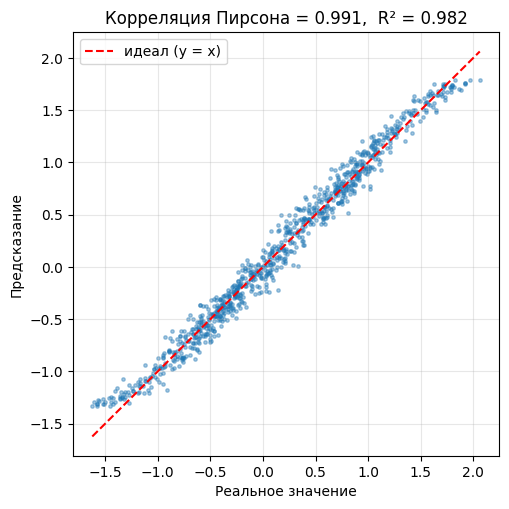

In [12]:
corr = np.corrcoef(true, pred)[0, 1]                      # Пирсон
r2 = 1 - ((true - pred) ** 2).sum() / ((true - true.mean()) ** 2).sum()

plt.figure(figsize=(5.5, 5.5))
plt.scatter(true, pred, s=6, alpha=0.4)
lims = [min(true.min(), pred.min()), max(true.max(), pred.max())]
plt.plot(lims, lims, "r--", label="идеал (y = x)")
plt.xlabel("Реальное значение")
plt.ylabel("Предсказание")
plt.title(f"Корреляция Пирсона = {corr:.3f},  R² = {r2:.3f}")
plt.legend(); plt.grid(alpha=0.3); plt.show()

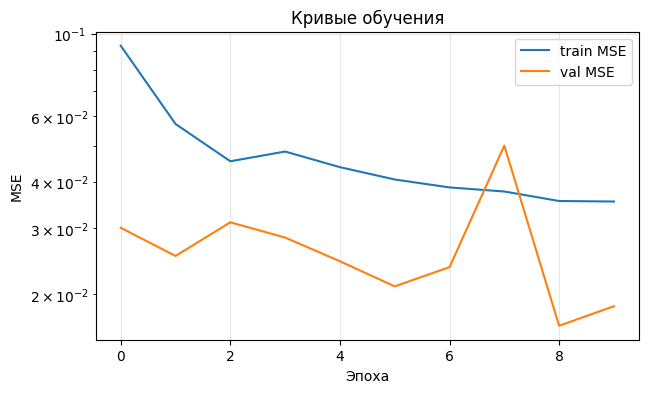

In [13]:
h = meta["history"]
plt.figure(figsize=(7, 4))
plt.plot(h["train"], label="train MSE")
plt.plot(h["val"], label="val MSE")
plt.yscale("log")
plt.xlabel("Эпоха"); plt.ylabel("MSE"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Кривые обучения"); plt.show()

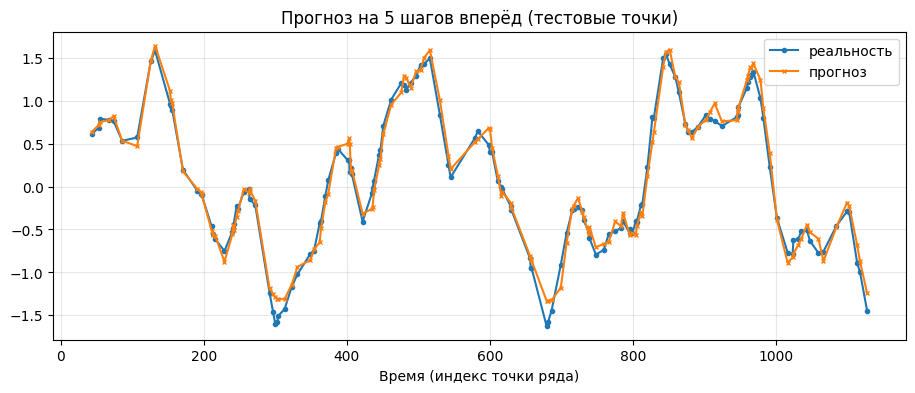

150 150 150


In [14]:
idx = np.array(test_loader.dataset.indices)               # позиции окон в исходном ряду
order = np.argsort(idx)
pos = idx[order] + cfg.seq_len + cfg.horizon - 1          # момент времени цели

n = 150
plt.figure(figsize=(11, 4))
plt.plot(pos[:n], true[order][:n], "o-", ms=3, label="реальность")
plt.plot(pos[:n], pred[order][:n], "x-", ms=3, label="прогноз")
plt.xlabel("Время (индекс точки ряда)"); plt.legend(); plt.grid(alpha=0.3) #номер точки в исходном ряду из 6000 точек
plt.title("Прогноз на 5 шагов вперёд (тестовые точки)"); plt.show() 

print(len(pos[:n]), len(true[order][:n]), len(pred[order][:n]))   # 150 150 150